# Temperature Prediction

## Objective
Predict the **temperature** based on humidity data.


## Dataset Overview
The dataset contains hourly or daily readings of humidity and temperature.


## Workflow
1. Load the dataset  
2. Explore and clean the data  
3. Train a regression model  
4. Evaluate predictions


In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
# Load the dataset
df = pd.read_csv("humidity.csv")
df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701548 entries, 0 to 701547
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   sensor_id    701548 non-null  int64  
 1   lat          701548 non-null  float64
 2   lon          701548 non-null  float64
 3   pressure     701548 non-null  float64
 4   temperature  701548 non-null  float64
 5   humidity     701548 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 32.1 MB


,sensor_id,lat,lon,pressure,temperature,humidity
0,2266,42.738,23.272,95270.27,23.46,62.48
1,2292,42.663,23.273,94355.83,23.06,59.46
2,3096,42.700,23.360,95155.81,26.53,44.38
3,3428,42.624,23.406,94679.57,28.34,38.28
4,3472,42.669,23.318,94327.88,26.31,46.37


## Exploratory Data Analysis


sensor_id      0
lat            0
lon            0
pressure       0
temperature    0
humidity       0
dtype: int64
           sensor_id            lat            lon       pressure  \
count  701548.000000  701548.000000  701548.000000  701548.000000   
mean     2835.419842      42.679722      23.333739   94965.292500   
std       798.018890       0.025568       0.039365    2577.210945   
min      1764.000000      42.622000      23.240000       0.000000   
25%      2224.000000      42.665000      23.310000   94528.017500   
50%      2323.000000      42.685000      23.332000   95005.480000   
75%      3474.000000      42.694000      23.360000   95405.132500   
max      4661.000000      42.738000      23.419000  164926.750000   

         temperature       humidity  
count  701548.000000  701548.000000  
mean       24.754990      48.348949  
std        14.013001      20.907247  
min      -145.120000       0.000000  
25%        20.630000      34.140000  
50%        24.780000      48.350000

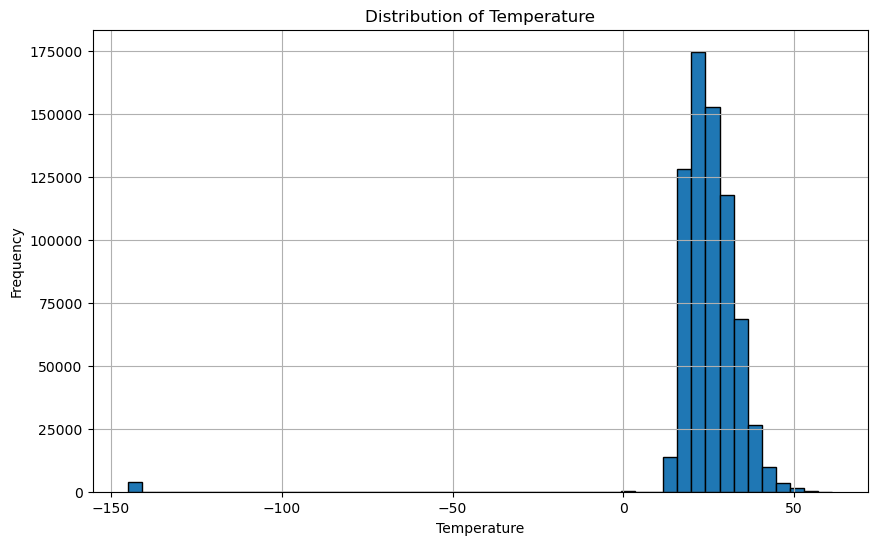

In [ ]:
# Check for missing values
print(df.isnull().sum())   #has 0 missing values

#describe the dataset of summary statistics
print(df.describe()) # it provides the descriptive statistics for all the numerical columns in this data frame.


# Display summary statistics with histograms
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.hist(df['temperature'], bins=50,edgecolor='black')
plt.title('Distribution of Temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


***The output of isnull().sum() shows that it have 0 missing values in each of these columns. It means that dont't need to worry about handling missing values for this data set, at least not in the initial stages***
*** . Describe() will provide you with respectuve statistics with all the numerical columns in the data frame, such as count, mean, standard deviation, minimum, maximum, and quartiles***
*sensor id: Range from 1 to 4461, with a mean of around 2835.

*lat: The latitue value seems to be clustered around 42.67, with relatively small standard deviation. The range is from 42.63 to 42.73. This suggests the sensors are located around the fairly limited geograohical area in the terms of latitude.

*lon: Similarly, The longitude values are centered around 23.33, with a small standard deviationand a narrow range (23.27 to 23.42). This reinforces the idea of a geographiclly located sets of sensors.

*pressure: The pressure readings have a wide range, from 0 to maximum of 164926.75 this mean is around 94965. This large range might indicate different units or potential outliners that need further investigation. A pressure of 0 seems unrealistic for typical atmospheric pressure.

*temperature: The temperature readings have a mean of about 24.75 degrees, with a standard deviation of 14.01. The minimum temperature is -145.12, which seems extremely low and could be an error or a reading in a different unit. The maximum temperature is 61.17, which is also quite high but potentially plausible in some environments. 
*humidity: The humidity values range from 0% to 100%, with a mean of around 48.35%. This seems like a reasonable range for humidity data.
Next Steps Based on These Observations:
Given the potentially unusual minimum temperature and the wide range of pressure values (including a minimum of 0), it would be a good idea to investigate these columns further.

***Histogram of the temperature data***
        * Main Cluster: The vast majority of your temperature readings are clustered between approximately 10 and 40 degrees. This likely represents the typical temperature range recorded by your sensors.

        * Extreme Low Value: There's a single bar far to the left, indicating the presence of that extremely low temperature value around -145 degrees. This value stands out significantly from the rest of the data and strongly suggests an error or a reading in an incorrect unit.

In [ ]:
#Defines The Range of Valid lower and upper bounds for temperature
lower_bound = -20
upper_bound = 50

#creates a new Data Frame with only hte rows that have valid temperature values.
df_valid_temp = df[(df['temperature'] >= lower_bound) & (df['temperature'] <= upper_bound)] 

#print the shape of the original and filtered data frames
print(f"Original DataFrame shape:{df.shape}")
print(f"DataFrame with valid temperature range ({lower_bound} to {upper_bound}) : {df_valid_temp.shape}")

Original DataFrame shape:(701548, 6)
DataFrame with valid temperature range (-20 to 50) : (696468, 6)


***This means that 701548 - 696468 = 5080 rows were removed because their temperature values were outside the -20 to 50 degrees Celsius range***
that seems like a significant number of rows. it might be worth double-checking the histogram of the original data to see if there were other unusual temperature readings beside the very low one.
It might be a great idea of to now plot the histogram of the 'temperature' column from the df_valid_temp DataFrame to see the distribution after this filtering. you can use the same histogram code, just to make sure to use df_valid_temp instead of df:

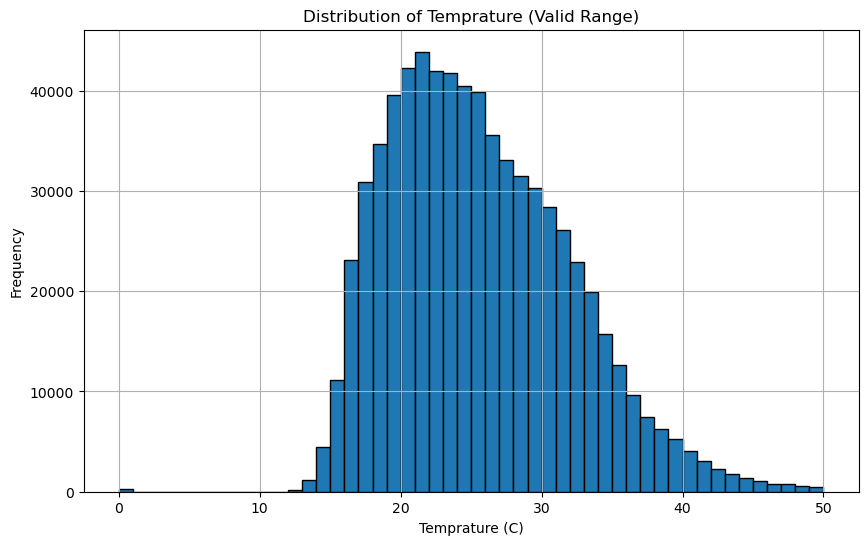

In [ ]:
#shows the Temperature distribution within our defined range
plt.figure(figsize = (10,6))
plt.hist(df_valid_temp['temperature'], bins = 50 , edgecolor = 'black')
plt.title('Distribution of Temprature (Valid Range)')
plt.xlabel('Temprature (C)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

***Histogram of the temperature data after filtering for the -20 to 50 degree Celcius Range.***
                * The distribution is now centered around the mid-20s.
                * It appears to be somewhat normally distributed, with a slight skew towards lower temperatures within the valid range.
                * The extreme outlier at -145 degrees is gone, as are any other readings outside our defined range.

In [ ]:
***To understand the distribution of the pressure data, let's create a histogram for it, similar to what we did for temperature. Run the following code in a new cell:***

   sensor_id     lat     lon  pressure  temperature  humidity
0       2266  42.738  23.272  95270.27        23.46     62.48
1       2292  42.663  23.273  94355.83        23.06     59.46
2       3096  42.700  23.360  95155.81        26.53     44.38
3       3428  42.624  23.406  94679.57        28.34     38.28
4       3472  42.669  23.318  94327.88        26.31     46.37
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701548 entries, 0 to 701547
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   sensor_id    701548 non-null  int64  
 1   lat          701548 non-null  float64
 2   lon          701548 non-null  float64
 3   pressure     701548 non-null  float64
 4   temperature  701548 non-null  float64
 5   humidity     701548 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 32.1 MB
None


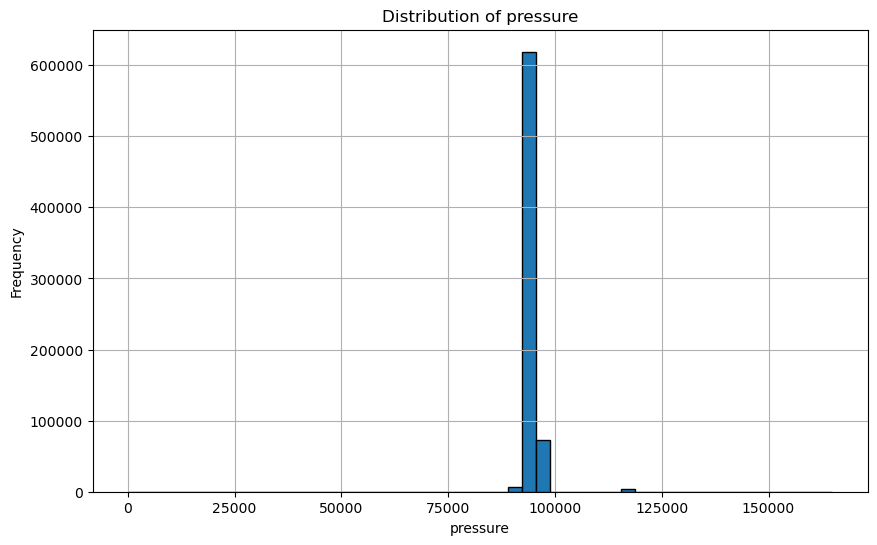

In [ ]:
#pressure between 0 and very high value change

import pandas as pd
import matplotlib.pyplot as plt
print(df.head())
print(df.info())
df = pd.read_csv(r'D:\PROJECT\HUMIDITY PROJECCT\humidity.csv')
# shows the distribution of pressur column.
plt.figure(figsize = (10 , 6))
plt.hist(df['pressure'] , bins = 50 , edgecolor = 'black')
plt.title('Distribution of pressure')
plt.xlabel('pressure')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

* There's a significant peak in the pressure readings around the 95,000 mark. This likely represents the typical atmospheric pressure recorded by your sensors in their specific units.
* There are also readings at much lower values, including some very close to 0, as we noted in the df.describe() output. These very low readings are still suspicious for atmospheric pressure.
* It's hard to tell from this view if there are extremely high pressure readings, but the df.describe() output indicated a maximum of over 160,000.

***Histogram of the pressure data***
                     * Dominant Peak: As suspected, there's a very strong peak centered around 95,000. This represents the vast majority of your pressure readings.
                     * Secondary Peaks: There are smaller peaks at lower pressure values, particularly around 0 and perhaps in the 80,000 range.
                     * High End: It's difficult to see the extreme high end from this view, but we know from df.describe() that the maximum is very high.
The presence of pressure readings close to 0 is still concerning for typical atmospheric pressure. These are likely erroneous. The secondary peak around 80,000 might represent a different set of conditions or perhaps a different unit if the data comes from various sources, although that seems less likely given the dominant peak

In [ ]:
#Flitering the data where the pressure falls within a reasonable range around 70,000 to 110,000 pascals.

# Defines the lower and upper bounds for the valid pressure range 
lower_pressure_bound = 70000
upper_pressure_bound = 110000

#Creates a new DataFrame containing only the rows from the original DF where the pressure is within the defined range.
df_valid_pressure = df[(df['pressure'] >= lower_pressure_bound) & (df['pressure'] <= upper_pressure_bound)]

#Prints the shapes to show how many rows were kept.
print(f"Original DataFrame Shape: {df.shape}" )
print(f"DataFrame with valid pressure range ({lower_pressure_bound} to {upper_pressure_bound}) : {df_valid_pressure.shape}")

Original DataFrame Shape: (701548, 6)
DataFrame with valid pressure range (70000 to 110000) : (697545, 6)


* Original DataFrame shape: (701548, 6)
* DataFrame with valid pressure range (70000 to 110000): (697545, 6)

***This means that 701548 - 697545 = 4003 rows were removed based on the pressure filter.***

In [ ]:
#Lets apply both the temp and pressure filters together, as discussed , Here is a code for clarity.
lower_temp_bound = -20
upper_temp_bound = 50

#creates a data frame within the valid range(-20 to 50 degree celsius)
df_valid_temp = df[(df['temperature'] >= lower_temp_bound) & (df['temperature'] <= upper_temp_bound)]

lower_pressure_bound = 70000
upper_pressure_bound = 110000

#Creates dataframe(which already has valid temperature)and filtering it further based on the pressure column. 
df_cleaned = df_valid_temp[(df_valid_temp['pressure'] >= lower_pressure_bound) & (df_valid_temp['pressure'] <= upper_pressure_bound)]

print(f"Original DataFrame Shape : {df.shape}")
print(f"DataFrame with valid temperature ({lower_temp_bound} to {upper_temp_bound} shape : {df_valid_temp.shape}")
print(f"DataFrame with valid temperature and pressure shape : {df_cleaned.shape}")

Original DataFrame Shape : (701548, 6)
DataFrame with valid temperature (-20 to 50 shape : (696468, 6)
DataFrame with valid temperature and pressure shape : (696206, 6)


***So, we have successfully filtered the data, and df_cleaned now contains 696,206 rows that satisfy both our temperature and pressure criteria.***

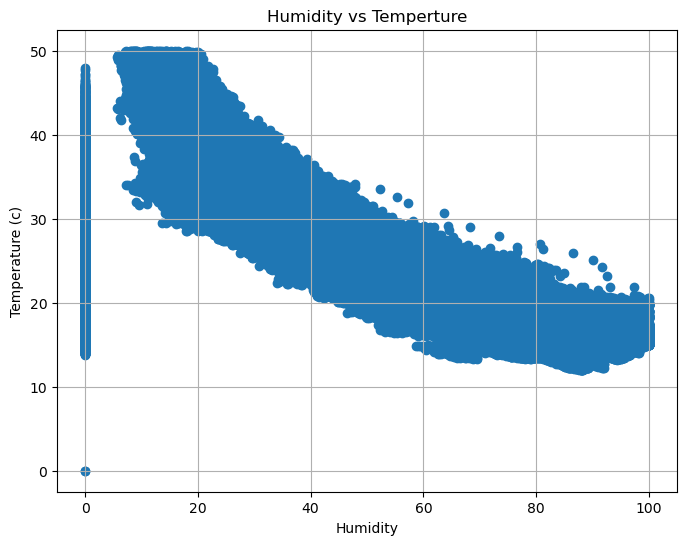

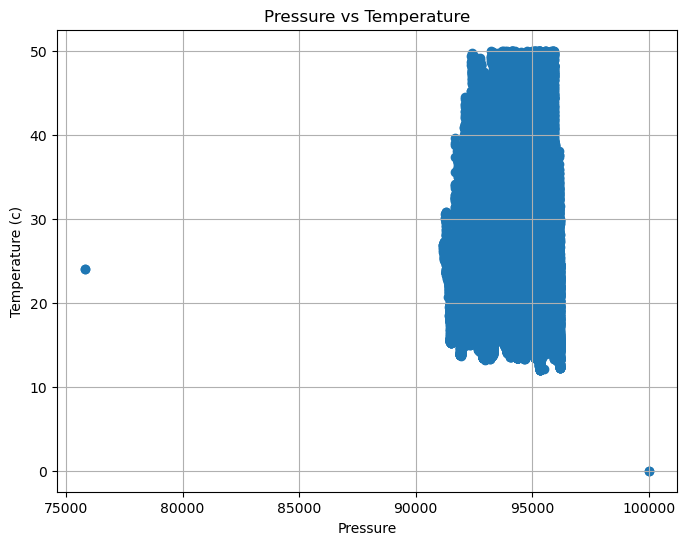

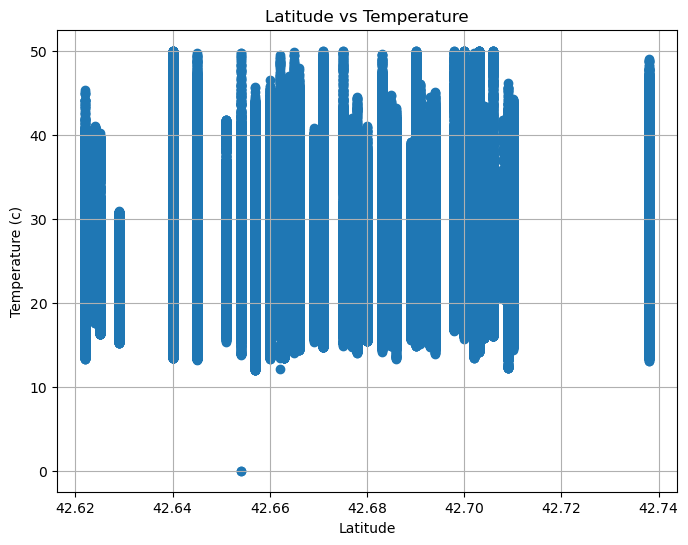

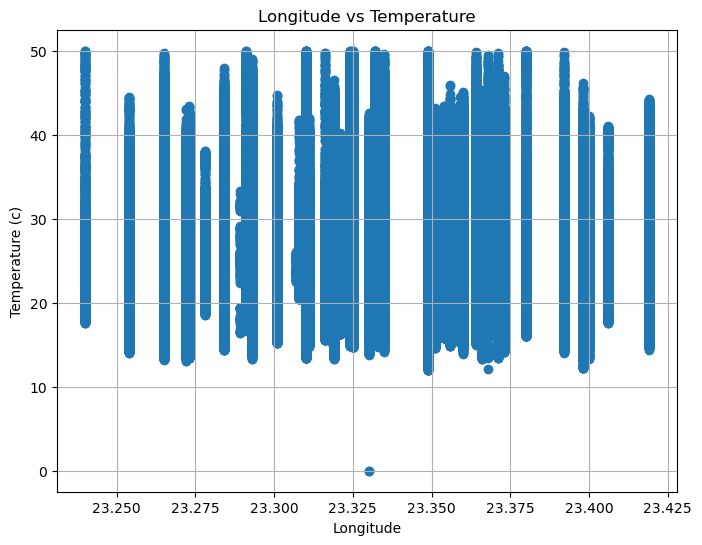

In [ ]:
# Scatter plot to observe relationship between the features('Humidity', 'Pressure', 'Lat', 'Lon') and the target variable Temperature using this cleaned DF.

# scatter plot

import matplotlib.pyplot as plt

#scatter plot for humidity vs temperature

plt.figure(figsize = (8 , 6))
plt.scatter(df_cleaned['humidity'] , df_cleaned['temperature'])
plt.title('Humidity vs Temperture')
plt.xlabel('Humidity')
plt.ylabel('Temperature (c)')
plt.grid(True)
plt.show()

#scatter plot for pressure vs temperature 
plt.figure(figsize = (8 , 6))
plt.scatter(df_cleaned['pressure'] , df_cleaned['temperature'])
plt.title('Pressure vs Temperature')
plt.xlabel('Pressure')
plt.ylabel('Temperature (c)')
plt.grid(True)
plt.show()

#scatter plot for latitude vs temperature
plt.figure(figsize = (8 , 6))
plt.scatter(df_cleaned['lat'], df_cleaned['temperature'])
plt.title('Latitude vs Temperature')
plt.xlabel('Latitude')
plt.ylabel('Temperature (c)')
plt.grid(True)
plt.show()

#scatter plot for longitude vs temperature
plt.figure(figsize = (8 , 6))
plt.scatter(df_cleaned['lon'] , df_cleaned['temperature'])
plt.title('Longitude vs Temperature')
plt.xlabel('Longitude')
plt.ylabel('Temperature (c)')
plt.grid(True)
plt.show()

 ***Scatter plot for all four observations***
 
 * Humidity vs. Temperature: Shows a general downward trend. As humidity increases, temperature tends to decrease. The relationship appears somewhat non-linear.
 * Pressure vs. Temperature: The majority of the data points are clustered around a narrow pressure range (around 94,000-95,000), making it difficult to discern a clear relationship with temperature from this central cluster. There are a few scattered points at lower pressures.
 * Latitude vs. Temperature: The data points are concentrated within a very narrow range of latitude values (around 42.6 to 42.75). There doesn't appear to be a strong linear trend between latitude and temperature within this limited range. The temperature seems to fluctuate across this narrow band of latitude.
 * Longitude vs. Temperature: Similar to latitude, the longitude values are also within a small range (around 23.25 to 23.4). Again, there's no obvious strong linear relationship between longitude and temperature within this confined geographical area. Temperature seems to vary across this narrow band of longitude.

 * Humidity seems to show the most discernible relationship with temperature (a negative correlation). It might be a useful feature for the model.
 * Pressure's relationship with temperature is less clear from the main cluster. The scattered lower pressure points might indicate something, but the dominant cluster doesn't show a strong trend.
 * Latitude and Longitude show very little apparent linear correlation with temperature, likely due to the sensors being located in a geographically small area. These might not be very strong predictors on their own.

## Data Preprocessing

In [ ]:
# Define features and target
from sklearn.model_selection import train_test_split

#define the feature(independent variable)
x = df_cleaned[['humidity']] # note the double square bracket is to make it a data frame

#define the target(dependent variable)
y = df_cleaned['temperature']

# Train-test split, Split your data into traing and testing sets.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

#print the shape of the training and testing sets.
print(f"shape of X_train: {x_train.shape}")
print(f"shape of X_test: {x_test.shape}")
print(f"shape of y_train: {y_train.shape}")
print(f"shape of y_test: {y_test.shape}")

shape of X_train: (556964, 1)
shape of X_test: (139242, 1)
shape of y_train: (556964,)
shape of y_test: (139242,)


 * X_train shape: (556964, 1) - This means you have 556,964 samples in your training set, and each sample has 1 feature ('humidity').
 * X_test shape: (139242, 1) - This means you have 139,242 samples in your testing set, each with 1 'humidity' feature.
 * y_train shape: (556964,) - This is the target variable ('temperature') for your training set, with 556,964 values.
 * y_test shape: (139242,) - This is the target 'temperature' for your testing set, with 139,242 values.

***now we will use linear regression class ***

## Model Training

In [ ]:
# Linear Regression
#create a linear regression model
model = LinearRegression()

#train the model using the training data
model.fit(x_train , y_train)

print("linear regression model trained!")

linear regression model trained!


## Evaluation


In [ ]:
# Predict

# Make predictions on the test set 
y_pred = model.predict(x_test)

# Print the first few predictions to see the output
print("First few predictions:")
print(y_pred[:5])
print("\nFirst few actual temperatures (from test set):")
print(y_test[:5].values)

First few predictions:
[25.07158072 22.60444131 37.12306712 31.86397614 23.39975344]

First few actual temperatures (from test set):
[22.71 25.47 20.53 36.84 20.9 ]


* Predictions: [25.07, 22.60, 37.12, 31.86, 23.40]
* Actual Temperatures: [22.71, 25.47, 20.53, 36.84, 20.90]

***It's difficult to judge the model's overall performance from just a few values, but we can see that there are differences between the predictions and the actual values***

Common regression metrics include:
 * Mean Squared Error (MSE): The average of the squared differences between the predicted and actual values.
 * Root Mean Squared Error (RMSE): The square root of the MSE, providing an error in the same units as the target variable (temperature).
 * R-squared (Coefficient of Determination): Represents the proportion of the variance in the dependent variable that is predictable from the independent variable(s).(it ranges from 0 to 1) with higher values indicating better fit.

***we will use some metrics to quantitatively evaluate the model's performance. Common metrics for regression tasks include Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared. We'll likely calculate these in the subsequent steps.***

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score 
import numpy as np

#calculate mean squared error(MSE)
mse = mean_squared_error(y_test,y_pred)
print(f"Mean Squared Error (mse): {mse:.2f}")

#calculate root mean squared error (rmse)
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error(rmse): {rmse:.2f}")

#calculate R-squared
r_squared = r2_score(y_test,y_pred)
print(f"R-Squared (R2):{r_squared:.2f}")

# output will give u the quantitative assesment of how well your linear agression model is performing on the test data.

Mean Squared Error (mse): 16.21
Root Mean Squared Error(rmse): 4.03
R-Squared (R2):0.60


***Okay, here are the evaluation metrics for your linear regression model (using only 'humidity' as a feature):***
 * Mean Squared Error (MSE): 16.21
 * Root Mean Squared Error (RMSE): 4.03
 * R-squared (R²): 0.60

 * MSE: On average, the squared difference between your model's predictions and the actual temperatures is 16.21.
 * RMSE: This is the square root of the MSE and is in the same units as the temperature (°C). An RMSE of 4.03 means that, on average, your model's predictions are about 4.03 degrees Celsius away from the actual temperatures.
 * R-squared: A value of 0.60 indicates that approximately 60% of the variance in the temperature can be explained by the humidity. The remaining 40% is explained by other factors not included in your model (or inherent randomness).

*** Adding pressure feature to your linear regression model. *** 

In [ ]:
#define features (humidity and pressure)
x = df_cleaned[['humidity','pressure']]
y = df_cleaned['temperature']

#split the data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

#create and train the linear regression model
model_multiple = LinearRegression()
model_multiple.fit(x_train, y_train)

#make predictions
y_pred_multiple = model_multiple.predict(x_test)

#evaluate the model
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
rmse_multiple = np.sqrt(mse_multiple)
r_squared_multiple = r2_score(y_test, y_pred_multiple)

print("Multiple Linear Regression (Humidity and Pressure)")
print(f"Mean Squared Error (mse): {mse_multiple:.2f}")
print(f"Root Mean Squared Error (rmse): {rmse:.2f}")
print(f"R-Squared (R2): {r_squared_multiple:.2f}")

Multiple Linear Regression (Humidity and Pressure)
Mean Squared Error (mse): 16.20
Root Mean Squared Error (rmse): 4.03
R-Squared (R2): 0.60


*** it appears to be same whie using the both 'humidity' and 'pressure' is same as the model using only humidity***

***This suggests that, in a simple linear fashion, adding the 'pressure' feature does not significantly improve the model's ability to predict temperature. This could be because the relationship between pressure and temperature is weak or non-linear, or perhaps the pressure information is already somewhat captured by the humidity.***

***lets make a polynomial regression using 'humidity' as a feature(we will try a degree of 2)(quadratic relationship)***

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#define the original feature(humidity)
x = df_cleaned[['humidity']]
y = df_cleaned['temperature']

#create polynomial features of degree 2
poly = PolynomialFeatures(degree=2)
x_poly = poly.fit_transform(x)

#split the data into training and testing sets
x_train_poly, x_test_poly, y_train, y_test = train_test_split(x_poly, y, test_size=0.2, random_state=42)

#create and train the linear regression model
model_poly = LinearRegression()
model_poly.fit(x_train_poly, y_train)

#make predictions on the test set
y_pred_poly = model_poly.predict(x_test_poly)

#evaluate the polynomial regression model
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r_squared_poly = r2_score(y_test, y_pred_poly)

print("Polynomial Regression (Hummidity, Degree 2)")
print(f"Mean Squared Error(mse): {mse_poly:.2f}")
print(f"root mean squared error(rmse): {rmse_poly:.2f}")
print(f"R-Squared (r2): {r_squared_poly:.2f}")

Polynomial Regression (Hummidity, Degree 2)
Mean Squared Error(mse): 14.91
root mean squared error(rmse): 3.86
R-Squared (r2): 0.63


***Using a polynomial (quadratic) relationship with 'humidity' has slightly improved the model's performance compared to the simple linear model (with or without pressure). This supports our earlier observation of a potential non-linear trend in the humidity vs. temperature scatter***

***here is a code to try a cubic(degree 3) polynomial regression with humidity:***

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#define the original feature(humidity)
x = df_cleaned[['humidity']]
y = df_cleaned['temperature']

#create polynomial feature of degree3
poly = PolynomialFeatures(degree=3)
x_poly = poly.fit_transform(x)

#split the data into training and testing sets
x_train_poly, x_test_poly, y_train, y_test = train_test_split(x_poly, y,test_size=0.2, random_state=42)

#create and train the linear regression model
model_poly_degree3 = LinearRegression()
model_poly_degree3.fit(x_train_poly, y_train)

#make predictions on the test set
y_pred_poly_degree3 = model_poly_degree3.predict(x_test_poly)

#evaluate the polynomial regression model(degree3)
mse_poly_degree3 = mean_squared_error(y_test, y_pred_poly_degree3)
rmse_poly_degree3 = np.sqrt(mse_poly_degree3)
r_squared_poly_degree3 = r2_score(y_test, y_pred_poly_degree3)

print("PolynomialRegression (Humidity, Degree3)")
print(f"Mean Squared Error (mse): {mse_poly_degree3:.2f}")
print(f"Root Mean Squared Error(rmse): {rmse_poly_degree3:.2f}")
print(f"R-Squared(r2): {r_squared_poly_degree3:.2f}")

PolynomialRegression (Humidity, Degree3)
Mean Squared Error (mse): 9.88
Root Mean Squared Error(rmse): 3.14
R-Squared(r2): 0.76


***This suggests that the relationship between humidity and temperature is indeed likely non-linear, and a cubic polynomial is capturing it better than a linear or quadratic one***

***adding pressure to the current cubic polynomial model***

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

#define the original features (humidity,preassure)
x = df_cleaned[['humidity','pressure']]
y = df_cleaned['temperature']

#create polynomial features of degree3 for humidity
poly = PolynomialFeatures(degree=3, include_bias=False)#include_bias=False to avoid redundant constant term
x_poly_humidity = poly.fit_transform(x[['humidity']])

#combine polynomial humidity features with pressure
x_extended = np.concatenate((x_poly_humidity, x[['pressure']].values), axis=1)
x_extended_df = pd.DataFrame(x_extended, columns=['humidity_1', 'humidity_2','humidity_3','pressure'])#create a data frame for splitting

#split the data
x_train_extended, x_test_extended, y_train, y_test = train_test_split(x_extended_df, y, test_size=0.2, random_state=42)

#create and train the linear regression model
model_extended = LinearRegression()
model_extended.fit(x_train_extended, y_train)

#make predictions
y_pred_extended = model_extended.predict(x_test_extended)

#evaluate the model
mse_extended = mean_squared_error(y_test, y_pred_extended)
rmse_extended = np.sqrt(mse_extended)
r_squared_extended = r2_score(y_test, y_pred_extended)

print("PolynomialRegression (humidity, degree3) + pressure")
print(f"Mean Squared Error(mse): {mse_extended:.2f}")
print(f"Root Mean Squared Error(rmse): {rmse_extended:.2f}")
print(f"R-Squared (r2): {r_squared_extended:.2f}")


PolynomialRegression (humidity, degree3) + pressure
Mean Squared Error(mse): 9.85
Root Mean Squared Error(rmse): 3.14
R-Squared (r2): 0.76


***it provides some additional predicitive power when pressure combines with the non-linear model***

***adding latitude and longitude to the current (cubic model + pressure) ***

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

#define the original features(humidity, pressure, latitude, longitude)
x = df_cleaned[['humidity','pressure','lat','lon']]
y = df_cleaned['temperature']

#create the polynomial features of degree3 for humidity
poly = PolynomialFeatures(degree=3, include_bias=False)
x_poly_humidity = poly.fit_transform(x[['humidity']])

#combine polynomial humidity features with pressure, latitude, longitude
x_extended =  np.concatenate((x_poly_humidity, x[['pressure', 'lat', 'lon']].values),axis=1)
x_extended_df = pd.DataFrame(x_extended, columns = ['humidity_1', 'humidity_2', 'humidity_3','pressure', 'lat', 'lon'])

#split the data
x_train_extended, x_test_extended, y_train, y_test = train_test_split(x_extended_df, y, test_size=0.2, random_state=42)

#create and train the linear regression model
model_extended_loc = LinearRegression() 
model_extended_loc.fit(x_train_extended, y_train)

#make predictions 
y_pred_extended_loc = model_extended_loc.predict(x_test_extended)

#evaluate the model
mse_extended_loc = mean_squared_error(y_test, y_pred_extended_loc)
rmse_extended_loc = np.sqrt(mse_extended_loc)
r_squared_extended_loc = r2_score(y_test, y_pred_extended_loc)

print("Polynomial Regression(Humidity, Dregree3) + pressure + latitude + longitude")
print(f"Mean Squared Error (mse): {mse_extended_loc:.2f}")
print(f"Root Mean Squared Error (rmse): {rmse_extended_loc:.2f}")
print(f"R-Squared (r2): {r_squared_extended_loc:.2f}")

Polynomial Regression(Humidity, Dregree3) + pressure + latitude + longitude
Mean Squared Error (mse): 9.40
Root Mean Squared Error (rmse): 3.07
R-Squared (r2): 0.77


***adding location data is not as large as the improvement from adding the polynomial features of humidity or pressure, it suggest that there might be some stubtle geographical patterns in the temperature that the model is now capturing***

***here is the code to generate a scatter plot of the predicted vs actual temperature***

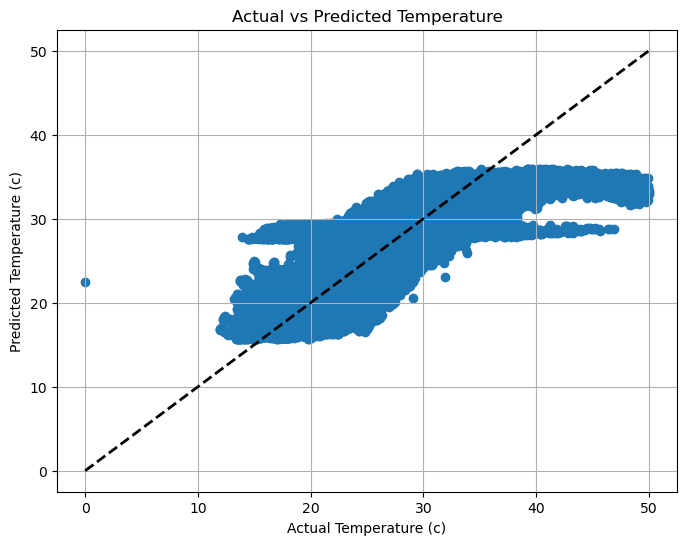

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8 , 6))
plt.scatter(y_test, y_pred_extended_loc)
plt.xlabel('Actual Temperature (c)')
plt.ylabel('Predicted Temperature (c)')
plt.title('Actual vs Predicted Temperature')
plt.grid(True)

#add a diagonal line for prefect predictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

 ***scatter plot of predicted temperature vs actual temperature***
 * General Trend: There is a general positive correlation, meaning that as the actual temperature increases, the predicted temperature also tends to increase. The points are somewhat clustered around the diagonal line (which represents perfect predictions).
 * Spread of Predictions: The predictions show a noticeable spread around the diagonal line, indicating that the model is not perfectly accurate. There are errors in both overestimation and underestimation of the temperature.
 * Density of Points: The majority of the data points seem to be concentrated in the mid-range of temperatures (around 20°C to 35°C), which suggests the model might be performing better in this range compared to the extremes.
 * Potential Non-Linearity: The overall shape of the scatter plot doesn't perfectly align with a straight line. There might be some remaining non-linear relationships that our current model isn't fully capturing. For instance, at lower actual temperatures, the model seems to have a wider range of predictions.

***trying higher degree polynomial for humidity(degree 4)***

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define the original features
X = df_cleaned[['humidity', 'pressure', 'lat', 'lon']]
y = df_cleaned['temperature']

# Create polynomial features of degree 4 for humidity
poly = PolynomialFeatures(degree=4, include_bias=False)
X_poly_humidity = poly.fit_transform(X[['humidity']])

# Combine polynomial humidity features with other features
X_extended = np.concatenate((X_poly_humidity, X[['pressure', 'lat', 'lon']].values), axis=1)
X_extended_df = pd.DataFrame(X_extended, columns=['humidity_1', 'humidity_2', 'humidity_3', 'humidity_4', 'pressure', 'lat', 'lon'])

# Split the data
X_train_extended, X_test_extended, y_train, y_test = train_test_split(X_extended_df, y, test_size=0.2, random_state=42)

# Create and train the linear regression model
model_extended_degree4 = LinearRegression()
model_extended_degree4.fit(X_train_extended, y_train)

# Make predictions
y_pred_extended_degree4 = model_extended_degree4.predict(X_test_extended)

# Evaluate the model
mse_extended_degree4 = mean_squared_error(y_test, y_pred_extended_degree4)
rmse_extended_degree4 = np.sqrt(mse_extended_degree4)
r_squared_extended_degree4 = r2_score(y_test, y_pred_extended_degree4)

print("Polynomial Regression (Humidity, Degree 4) + Pressure + Latitude + Longitude")
print(f"Mean Squared Error (MSE): {mse_extended_degree4:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_extended_degree4:.2f}")
print(f"R-squared (R²): {r_squared_extended_degree4:.2f}")

Polynomial Regression (Humidity, Degree 4) + Pressure + Latitude + Longitude
Mean Squared Error (MSE): 7.55
Root Mean Squared Error (RMSE): 2.75
R-squared (R²): 0.81


 * The MSE has dropped considerably, indicating that the average squared error in our predictions is now much smaller.
 * The RMSE has also decreased significantly, meaning our model's predictions are now, on average, only about 2.75 degrees Celsius away from the actual temperatures.
 * The R-squared has jumped to 0.81, which means our model now explains a substantial 81% of the variance in the temperature data. This is a very good improvement!
 At this point, you have a reasonably well-performing model.

***lets visualize the predictions of this degree4***

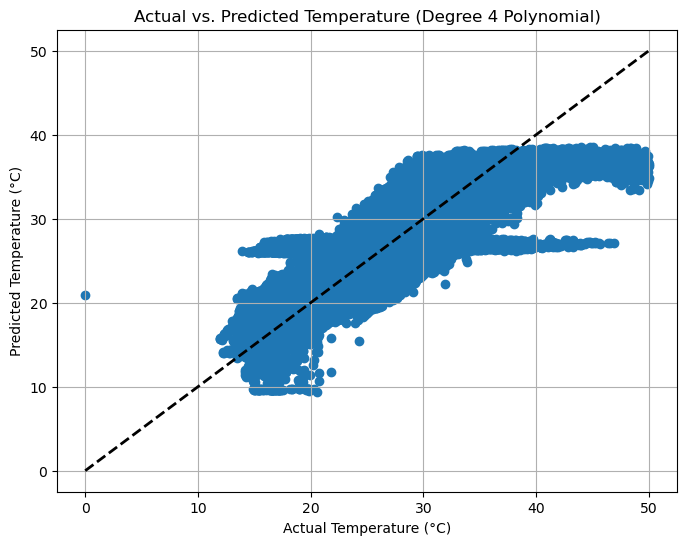

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_extended_degree4)
plt.xlabel('Actual Temperature (°C)')
plt.ylabel('Predicted Temperature (°C)')
plt.title('Actual vs. Predicted Temperature (Degree 4 Polynomial)')
plt.grid(True)

# Add a diagonal line for perfect predictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

 * Closer to the Diagonal: The points appear to be much more tightly clustered around the diagonal line (representing perfect predictions) compared to our previous model. This visually confirms the significant improvement in accuracy indicated by the evaluation metrics.
 * Reduced Spread: The spread of the predictions for a given actual temperature seems to be smaller, meaning the model's predictions are more consistent.
 * Better Coverage Across Temperature Range: The model appears to be performing reasonably well across a wider range of actual temperatures, although there might still be some areas with slightly more spread.
 * No Obvious Systematic Bias: There isn't a clear indication of the model consistently over- or under-predicting temperatures in a specific range.

## Conclusion
 * A simple linear regression model using only humidity explained approximately 60% of the temperature variance (R-squared = 0.60).
 * Polynomial regression was explored to capture the non-linear relationship between humidity and temperature.
 * Incorporating a degree 4 polynomial for humidity, along with pressure, latitude, and longitude, significantly improved the model.
 * The final model achieved an R-squared of approximately 0.81, explaining a much larger portion of the temperature variance.
 * Further improvements could be explored by considering higher-degree polynomials, interaction terms, or more advanced regression techniques.
 * If the data has a temporal component, time series models could be investigated for time-dependent patterns



In [1]:
import pandas as pd
df = pd.read_csv(r'D:\PROJECT\HUMIDITY PROJECCT\humidity.csv')
new_data_point = df.iloc[0]  # Get the first row as a Series
new_humidity = new_data_point['humidity']
new_pressure = new_data_point['pressure']
new_latitude = new_data_point['lat']
new_longitude = new_data_point['lon']

In [4]:
import pandas as pd
import datetime
# Assuming your previous code to read the CSV and extract values is still in place

print(f"Current Humidity: {new_humidity}")
print(f"Current Pressure: {new_pressure}")
print(f"Latitude: {new_latitude}, Longitude: {new_longitude}")

# Generate a Google Maps link
google_maps_link = f"https://www.google.com/maps?q={new_latitude},{new_longitude}"
print(f"View on Google Maps: {google_maps_link}")

# Get the current date and time (assuming this reading was taken now)
current_datetime_ist = datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=5, minutes=30))) # India Standard Time
print(f"Data recorded on: {current_datetime_ist.strftime('%Y-%m-%d %H:%M:%S %Z%z')}")

# You would need to install the 'suntime' library: pip install suntime
from suntime import Sun

sun = Sun(float(new_latitude), float(new_longitude))
today_date = current_datetime_ist.date()
sunrise = sun.get_local_sunrise_time(today_date)
sunset = sun.get_local_sunset_time(today_date)

print(f"Approximate Sunrise Time (IST): {sunrise.strftime('%H:%M:%S') if sunrise else 'N/A'}")
print(f"Approximate Sunset Time (IST): {sunset.strftime('%H:%M:%S') if sunset else 'N/A'}")

# You could add more based on climate zones and typical weather in India for May
print("\nGeneral Information about India in May:")
print("- May is typically a pre-monsoon month in many parts of India.")
print("- Expect hot and dry conditions in several regions.")
print("- Coastal areas might experience higher humidity.")


Current Humidity: 62.48
Current Pressure: 95270.27
Latitude: 42.738, Longitude: 23.272
View on Google Maps: https://www.google.com/maps?q=42.738,23.272
Data recorded on: 2025-05-06 00:37:04 UTC+05:30+0530
Approximate Sunrise Time (IST): 03:15:36
Approximate Sunset Time (IST): 17:32:24

General Information about India in May:
- May is typically a pre-monsoon month in many parts of India.
- Expect hot and dry conditions in several regions.
- Coastal areas might experience higher humidity.


In [5]:
import sys
print(sys.executable)

c:\Users\arthi\anaconda\python.exe


In [3]:
!pip install suntime


  Using cached suntime-1.3.2-py3-none-any.whl.metadata (3.0 kB)
Using cached suntime-1.3.2-py3-none-any.whl (7.2 kB)
